## Step 8 - Explainability (gain, permutation, SHAP)

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.inspection import permutation_importance

In [2]:
from features import load_data, numeric_features, categorical_features

warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [3]:
X_dev, y_dev, X_test, y_test = load_data()

final_choice = json.load(open("results/final_choice.json"))
model_name = final_choice["model"]
threshold = final_choice["threshold"]
print("Final model:", model_name, "- threshold:", round(threshold, 3))

Final model: lightgbm - threshold: 0.376


In [4]:
pipeline = joblib.load("models/best_" + model_name + ".pkl")
model = pipeline.named_steps["classifier"]

# the model only sees the data after feature engineering + preprocessing
X_test_transformed = pipeline[:-1].transform(X_test)
feature_names = pipeline.named_steps["preprocessing"].get_feature_names_out()
feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]
X_test_transformed = pd.DataFrame(X_test_transformed, columns=feature_names)
print("Transformed test set:", X_test_transformed.shape)

Transformed test set: (9043, 50)


In [5]:
# 1. native importance (gain)
if model_name == "lightgbm":
    gain = model.booster_.feature_importance(importance_type="gain")
else:
    gain = model.feature_importances_
gain_importance = pd.Series(gain, index=feature_names).sort_values(ascending=False)
gain_importance = gain_importance / gain_importance.sum()
print("\nTop 10 gain importance (normalized):")
print(gain_importance.head(10).round(3))


Top 10 gain importance (normalized):
balance               0.108
day                   0.104
poutcome_success      0.094
age                   0.090
pdays                 0.073
contact_unknown       0.065
housing_yes           0.038
campaign              0.035
total_interactions    0.033
previous              0.026
dtype: float64


In [6]:
# 2. permutation importance on the raw columns, with the whole pipeline
perm = permutation_importance(pipeline, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=42, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("\nPermutation importance (drop of test PR-AUC when the column is shuffled):")
print(perm_importance.round(4))


Permutation importance (drop of test PR-AUC when the column is shuffled):
month        0.1049
poutcome     0.0844
contact      0.0794
day          0.0434
pdays        0.0279
housing      0.0162
campaign     0.0128
previous     0.0105
marital      0.0060
age          0.0056
balance      0.0048
education    0.0039
loan         0.0031
job          0.0020
default     -0.0001
dtype: float64


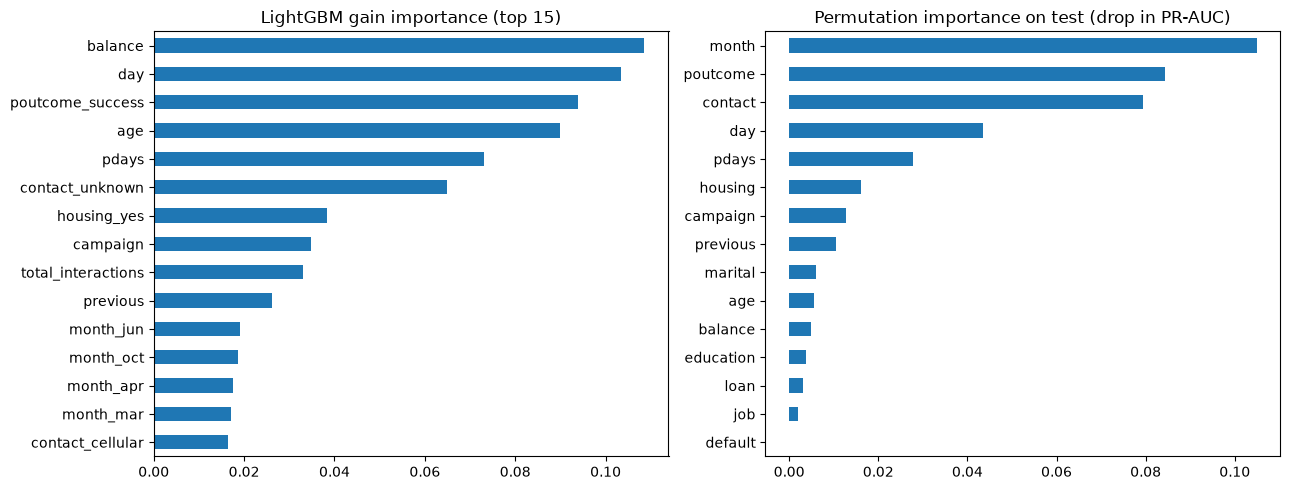

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
gain_importance.head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("LightGBM gain importance (top 15)")
perm_importance.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Permutation importance on test (drop in PR-AUC)")
plt.tight_layout()
plt.savefig("plots/gain_vs_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# 3. SHAP values on the test set
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_transformed)
if len(shap_values.shape) == 3:
    # random forest gives one value per class -> we keep class 1
    shap_values = shap_values[:, :, 1]
print("\nSHAP values shape:", shap_values.shape)


SHAP values shape: (9043, 50)


In [9]:
# the plots would show the scaled values (ex: age = -1.97), so we put back the real values
# for the numeric columns (they are the first columns of the transformed data)
X_test_engineered = pipeline.named_steps["engineering"].transform(X_test)
real_values = shap_values.data.copy()  # (the original array is read-only)
for j in range(len(numeric_features)):
    real_values[:, j] = X_test_engineered[numeric_features[j]].values
shap_values.data = real_values
print("Base value (average log-odds):", round(float(np.mean(shap_values.base_values)), 3))

Base value (average log-odds): -1.59


In [10]:
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_names).sort_values(ascending=False)
print("\nTop 10 mean |SHAP| :")
print(mean_abs_shap.head(10).round(4))

# one-hot cuts a variable like "month" in 12 columns, so its importance is split.
# SHAP values are additive -> SHAP of the original variable = sum of the SHAP of its columns
shap_by_variable = {}
for var in numeric_features + categorical_features:
    cols = []
    for j in range(len(feature_names)):
        if feature_names[j] == var or feature_names[j].startswith(var + "_"):
            cols.append(j)
    shap_by_variable[var] = np.abs(shap_values.values[:, cols].sum(axis=1)).mean()
shap_by_variable = pd.Series(shap_by_variable).sort_values(ascending=False)
print("\nMean |SHAP| by original variable (one-hot columns added together):")
print(shap_by_variable.round(4))
shap_by_variable.to_csv("results/shap_by_variable.csv", header=["mean_abs_shap"])


Top 10 mean |SHAP| :
contact_unknown     0.2736
contact_cellular    0.1561
housing_yes         0.1523
balance             0.1515
day                 0.1474
age                 0.1050
poutcome_success    0.1026
marital_married     0.0977
month_may           0.0824
campaign            0.0796
dtype: float64

Mean |SHAP| by original variable (one-hot columns added together):
contact                 0.4153
month                   0.2536
housing                 0.1523
balance                 0.1515
day                     0.1474
marital                 0.1449
poutcome                0.1078
age                     0.1050
campaign                0.0796
loan                    0.0598
pdays                   0.0568
education               0.0558
previous                0.0552
job                     0.0430
total_interactions      0.0426
previously_contacted    0.0122
is_negative_balance     0.0095
default                 0.0015
dtype: float64


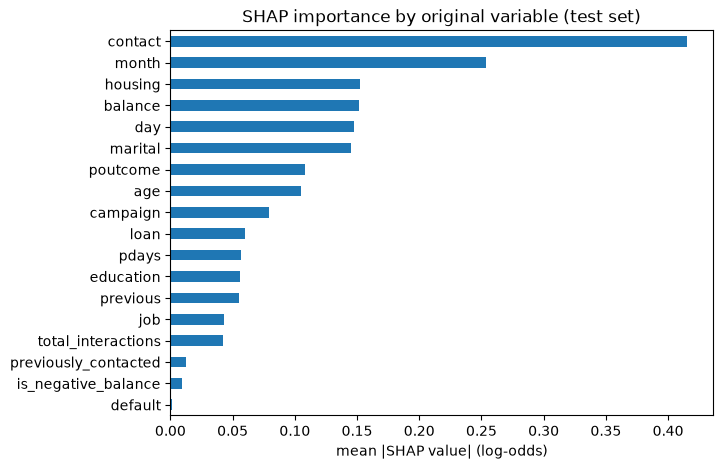

In [11]:
plt.figure(figsize=(7, 5))
shap_by_variable.sort_values().plot(kind="barh")
plt.xlabel("mean |SHAP value| (log-odds)")
plt.title("SHAP importance by original variable (test set)")
plt.savefig("plots/shap_by_variable.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
importance_table = pd.DataFrame({
    "gain_importance": gain_importance,
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=False)
importance_table.to_csv("results/shap_and_gain_importance.csv")
perm_importance.to_csv("results/permutation_importance.csv", header=["drop_in_pr_auc"])

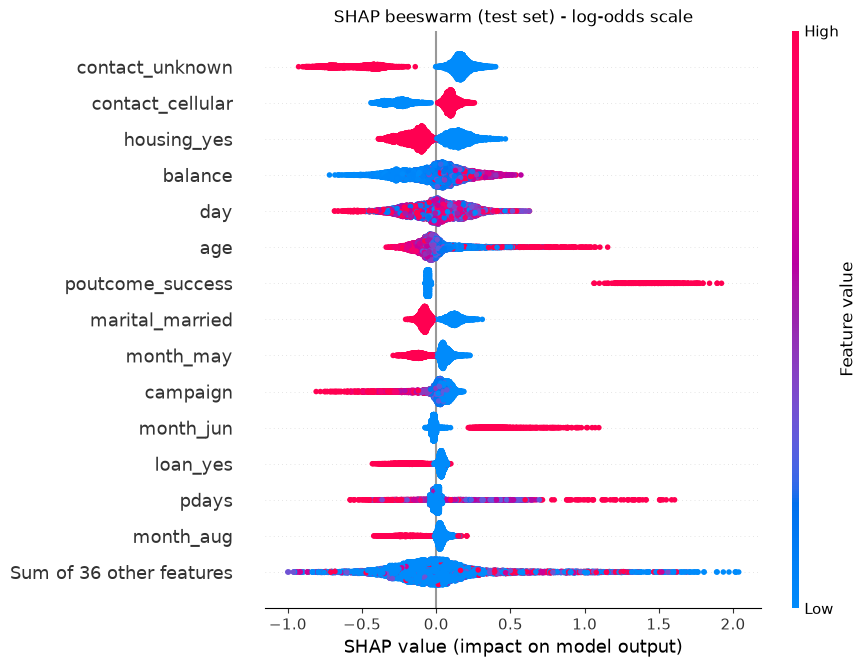

In [13]:
# global plots
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP beeswarm (test set) - log-odds scale")
plt.savefig("plots/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

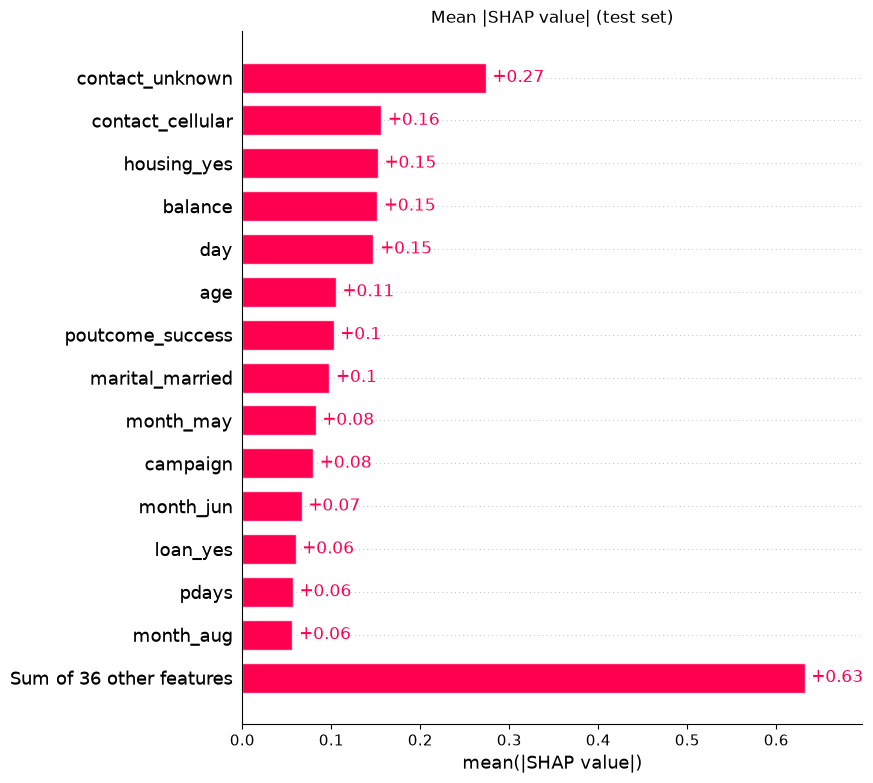

In [14]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Mean |SHAP value| (test set)")
plt.savefig("plots/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# 4. local explanations for 4 clients
proba = pipeline.predict_proba(X_test)[:, 1]
y_pred = (proba >= threshold).astype(int)
y_true = y_test.values

tp = np.where((y_pred == 1) & (y_true == 1))[0]
fn = np.where((y_pred == 0) & (y_true == 1))[0]
fp = np.where((y_pred == 1) & (y_true == 0))[0]
tn = np.where((y_pred == 0) & (y_true == 0))[0]

In [16]:
clients = {
    "true_positive": tp[np.argmax(proba[tp])],   # subscriber with the highest score
    "false_negative": fn[np.argmin(proba[fn])],  # subscriber the model missed the most
    "false_positive": fp[np.argmax(proba[fp])],  # non-subscriber with the highest score
    "true_negative": tn[np.argmin(proba[tn])],   # non-subscriber with the lowest score
}


===== true_positive - test row 2399 =====
predicted probability: 0.93 | real label: 1
{'age': 20, 'job': 'student', 'marital': 'single', 'education': 'secondary', 'default': 'no', 'balance': 215, 'housing': 'no', 'loan': 'no', 'contact': 'cellular', 'day': 24, 'month': 'feb', 'campaign': 1, 'pdays': 92, 'previous': 6, 'poutcome': 'success'}


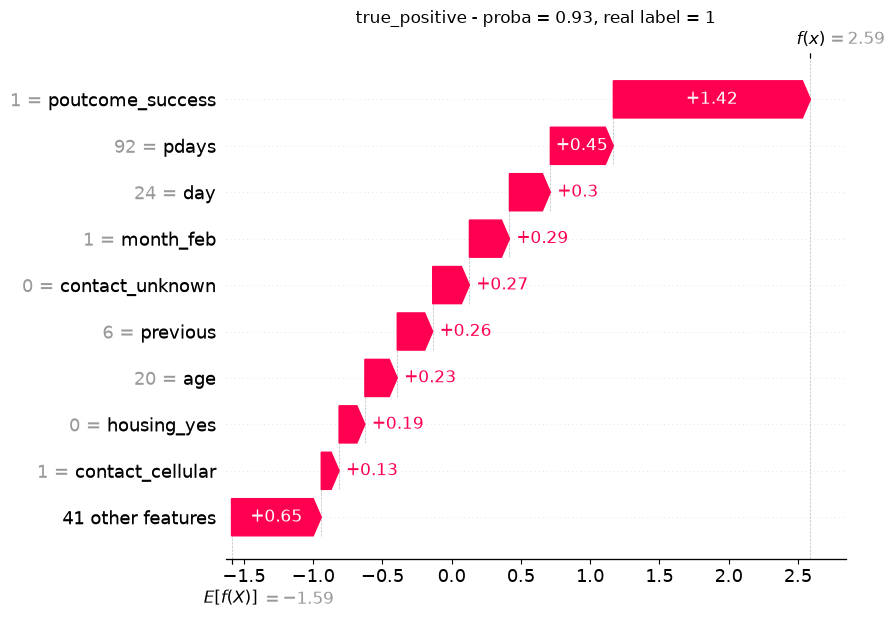


===== false_negative - test row 8231 =====
predicted probability: 0.038 | real label: 1
{'age': 55, 'job': 'housemaid', 'marital': 'married', 'education': 'primary', 'default': 'no', 'balance': 2152, 'housing': 'no', 'loan': 'no', 'contact': 'unknown', 'day': 19, 'month': 'jun', 'campaign': 2, 'pdays': -1, 'previous': 0, 'poutcome': 'unknown'}


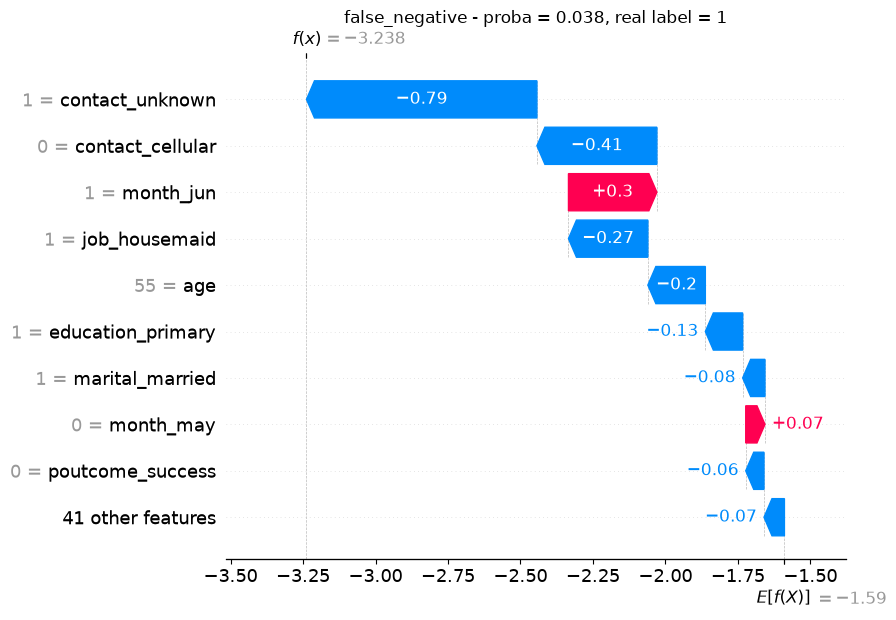


===== false_positive - test row 7422 =====
predicted probability: 0.904 | real label: 0
{'age': 25, 'job': 'student', 'marital': 'single', 'education': 'secondary', 'default': 'no', 'balance': 469, 'housing': 'no', 'loan': 'no', 'contact': 'cellular', 'day': 24, 'month': 'feb', 'campaign': 1, 'pdays': 187, 'previous': 2, 'poutcome': 'success'}


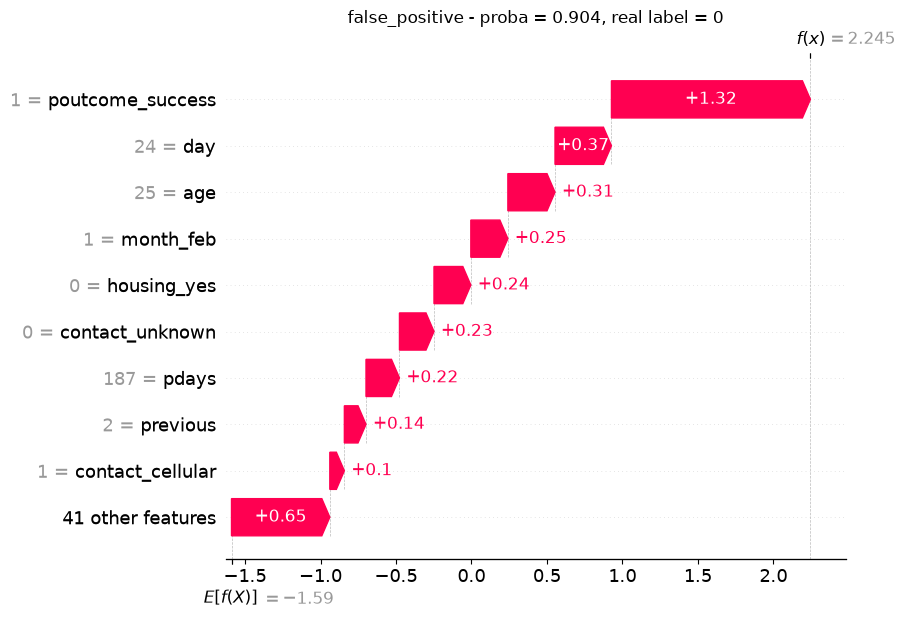


===== true_negative - test row 3014 =====
predicted probability: 0.013 | real label: 0
{'age': 49, 'job': 'blue-collar', 'marital': 'married', 'education': 'primary', 'default': 'no', 'balance': 2, 'housing': 'yes', 'loan': 'no', 'contact': 'unknown', 'day': 20, 'month': 'jun', 'campaign': 20, 'pdays': -1, 'previous': 0, 'poutcome': 'unknown'}


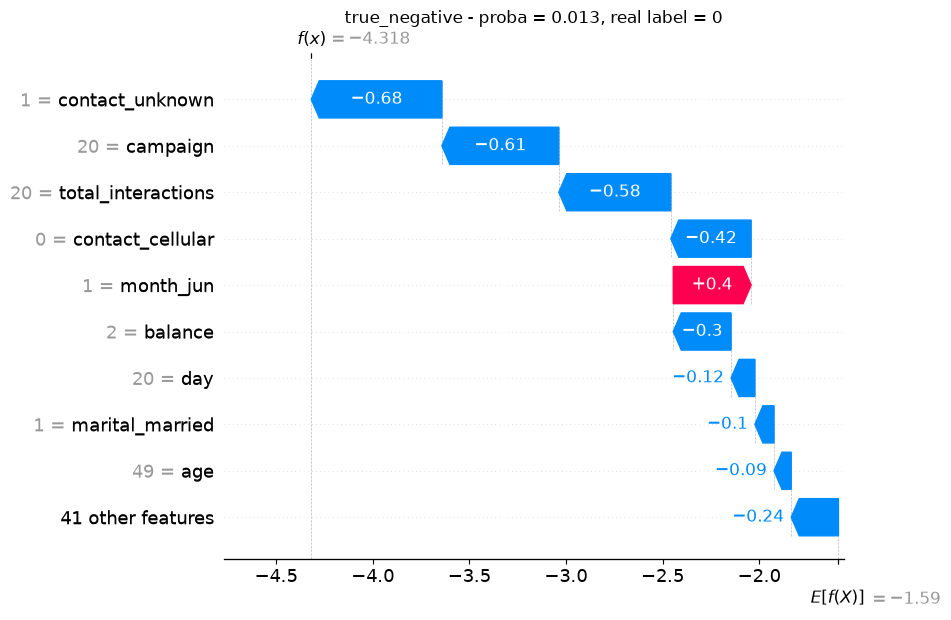

In [17]:
for case in clients:
    i = clients[case]
    print("\n=====", case, "- test row", i, "=====")
    print("predicted probability:", round(proba[i], 3), "| real label:", y_true[i])
    print(X_test.iloc[i].to_dict())
    shap.plots.waterfall(shap_values[i], max_display=10, show=False)
    plt.title(case + " - proba = " + str(round(proba[i], 3)) + ", real label = " + str(y_true[i]))
    plt.savefig("plots/shap_waterfall_" + case + ".png", dpi=150, bbox_inches="tight")
    plt.show()

In [18]:
print("\nSaved SHAP plots in plots/")


Saved SHAP plots in plots/
